Load Dataset dan Split Dataset

Membagi dataset dengan rasio 80% untuk training dan 20% untuk testing

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_val_predict
)

# =========================================================
# CONFIGURATION
# =========================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

DATA_PATH = os.path.join(
    "..",
    "data",
    "cleaned_processed.csv"
)

MODEL_DIR = "../models"

os.makedirs(MODEL_DIR, exist_ok=True)


# =========================================================
# LOAD DATA
# =========================================================

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

print("\nChurn distribution:")
print(df["Churn"].value_counts(dropna=False))


# =========================================================
# CLEAN TARGET
# =========================================================

df = df.dropna(subset=["Churn"]).copy()

if df.empty:
    raise ValueError(
        "Dataset kosong setelah menghapus baris dengan "
        "Churn NaN."
    )


# =========================================================
# FEATURES & TARGET
# =========================================================

X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)


# =========================================================
# TRAIN-TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)


# =========================================================
# SUMMARY
# =========================================================

print("\n=== DATA SPLIT ===")
print(f"Training : {X_train.shape}")
print(f"Testing  : {X_test.shape}")

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Dataset shape: (7043, 31)

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

=== DATA SPLIT ===
Training : (5634, 30)
Testing  : (1409, 30)

Training target:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target:
Churn
0    1035
1     374
Name: count, dtype: int64


Mendefinisikan Baseline Model yang Akan digunakan

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)
from xgboost import XGBClassifier


# =========================================================
# BASELINE MODELS
# =========================================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=500,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE
    ),

    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=RANDOM_STATE
    )
}

Training Baseline Model

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# =========================================================
# BASELINE TRAINING & EVALUATION
# =========================================================

results = []

trained_models = {}

for name, model in models.items():

    print(f"\n{'=' * 60}")
    print(f"TRAINING: {name}")
    print(f"{'=' * 60}")

    try:

        # -------------------------------------------------
        # TRAIN
        # -------------------------------------------------

        model.fit(X_train, y_train)

        # -------------------------------------------------
        # PREDICTION
        # -------------------------------------------------

        y_pred = model.predict(X_test)

        y_prob = model.predict_proba(X_test)[:, 1]

        # -------------------------------------------------
        # METRICS
        # -------------------------------------------------

        result = {
            "model": name,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(
                y_test,
                y_pred,
                zero_division=0
            ),
            "recall": recall_score(
                y_test,
                y_pred,
                zero_division=0
            ),
            "f1": f1_score(
                y_test,
                y_pred,
                zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_test,
                y_prob
            )
        }

        results.append(result)

        # Simpan model yang sudah dilatih
        trained_models[name] = model

        # -------------------------------------------------
        # CLASSIFICATION REPORT
        # -------------------------------------------------

        print(
            classification_report(
                y_test,
                y_pred,
                digits=4,
                zero_division=0
            )
        )

        print(
            f"ROC-AUC: {result['roc_auc']:.4f}"
        )

    except Exception as e:

        print(f"Error pada {name}: {e}")


TRAINING: Logistic Regression
              precision    recall  f1-score   support

           0     0.8488    0.8947    0.8711      1035
           1     0.6572    0.5588    0.6040       374

    accuracy                         0.8055      1409
   macro avg     0.7530    0.7268    0.7376      1409
weighted avg     0.7979    0.8055    0.8002      1409

ROC-AUC: 0.8420

TRAINING: Random Forest
              precision    recall  f1-score   support

           0     0.8308    0.8966    0.8625      1035
           1     0.6336    0.4947    0.5556       374

    accuracy                         0.7899      1409
   macro avg     0.7322    0.6956    0.7090      1409
weighted avg     0.7784    0.7899    0.7810      1409

ROC-AUC: 0.8261

TRAINING: Extra Trees
              precision    recall  f1-score   support

           0     0.8248    0.8821    0.8525      1035
           1     0.5960    0.4813    0.5325       374

    accuracy                         0.7757      1409
   macro avg     

Membandingkan Semua Model untuk dipilih model terbaik

In [53]:
# =========================================================
# MODEL COMPARISON
# =========================================================

results_df = (
    pd.DataFrame(results)
    .set_index("model")
    .sort_values(
        by="roc_auc",
        ascending=False
    )
)

print("\n=== BASELINE MODEL COMPARISON ===")
print(results_df.round(4))


=== BASELINE MODEL COMPARISON ===
                     accuracy  precision  recall      f1  roc_auc
model                                                            
Logistic Regression    0.8055     0.6572  0.5588  0.6040   0.8420
Random Forest          0.7899     0.6336  0.4947  0.5556   0.8261
XGBoost                0.7850     0.6079  0.5348  0.5690   0.8214
Extra Trees            0.7757     0.5960  0.4813  0.5325   0.7998


Menetapkan model terbaik yang akan digunakan

In [54]:
# =========================================================
# SELECT CANDIDATE MODEL
# =========================================================

candidate_model_name = "Logistic Regression"

candidate_model = trained_models[candidate_model_name]

print("\n=== CANDIDATE MODEL ===")
print(candidate_model_name)


=== CANDIDATE MODEL ===
Logistic Regression


Menampilkan Convusion Matrix untuk melihat sebaran dari hasil klasifikasi model


=== CONFUSION MATRIX ===
[[926 109]
 [165 209]]


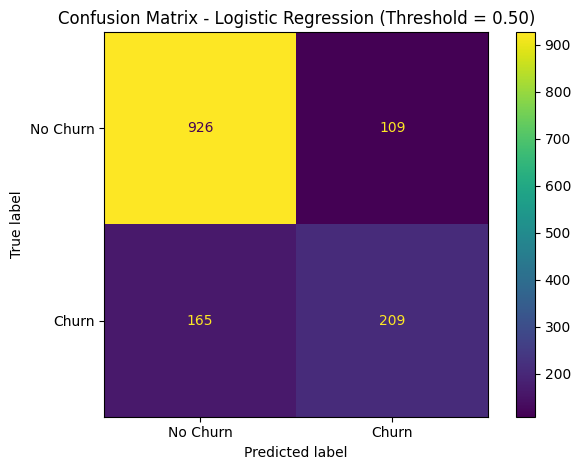

In [55]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt


# =========================================================
# BASELINE CONFUSION MATRIX
# =========================================================

y_prob = candidate_model.predict_proba(X_test)[:, 1]

y_pred_default = (
    y_prob >= 0.5
).astype(int)


cm = confusion_matrix(
    y_test,
    y_pred_default
)

print("\n=== CONFUSION MATRIX ===")
print(cm)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

plt.title(
    "Confusion Matrix - Logistic Regression "
    "(Threshold = 0.50)"
)

plt.tight_layout()
plt.show()

Melakukan Hyperparameter Tuning untuk mengoptimalkan model

In [56]:
# =========================================================
# CROSS-VALIDATION
# =========================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


# =========================================================
# BASE MODEL
# =========================================================

lr = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)


# =========================================================
# HYPERPARAMETER GRID
# =========================================================

param_grid = {

    "C": [
        0.01,
        0.1,
        1,
        10,
        100
    ],

    "penalty": [
        "l1",
        "l2"
    ],

    "solver": [
        "liblinear"
    ],

    "class_weight": [
        None,
        "balanced"
    ]
}


# =========================================================
# GRID SEARCH
# =========================================================

grid_search = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)


grid_search.fit(
    X_train,
    y_train
)


# =========================================================
# BEST RESULT
# =========================================================

print("\n=== BEST HYPERPARAMETERS ===")

print(
    grid_search.best_params_
)

print(
    f"\nBest CV ROC-AUC: "
    f"{grid_search.best_score_:.4f}"
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

=== BEST HYPERPARAMETERS ===
{'C': 10, 'class_weight': None, 'penalty': 'l2', 'solver': 'liblinear'}

Best CV ROC-AUC: 0.8463


Menampilkan Hadil Hyperparameter Tuning

In [57]:
# =========================================================
# GRID SEARCH RESULTS
# =========================================================

cv_results = pd.DataFrame(
    grid_search.cv_results_
)

cv_results = (
    cv_results[
        [
            "param_C",
            "param_penalty",
            "param_class_weight",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .sort_values(
        "mean_test_score",
        ascending=False
    )
)

print("\n=== TOP HYPERPARAMETER RESULTS ===")

print(
    cv_results
    .head(10)
    .round(4)
)


=== TOP HYPERPARAMETER RESULTS ===
    param_C param_penalty param_class_weight  mean_test_score  std_test_score
13     10.0            l2               None           0.8463          0.0128
16    100.0            l1               None           0.8463          0.0129
17    100.0            l2               None           0.8463          0.0129
12     10.0            l1               None           0.8463          0.0128
14     10.0            l1           balanced           0.8462          0.0127
15     10.0            l2           balanced           0.8461          0.0127
19    100.0            l2           balanced           0.8461          0.0128
18    100.0            l1           balanced           0.8461          0.0128
9       1.0            l2               None           0.8460          0.0124
8       1.0            l1               None           0.8459          0.0124


Mencari parameter terbaik

In [58]:
# =========================================================
# BEST MODEL
# =========================================================

best_lr = grid_search.best_estimator_

print("\n=== BEST LOGISTIC REGRESSION ===")
print(best_lr)


=== BEST LOGISTIC REGRESSION ===
LogisticRegression(C=10, max_iter=1000, random_state=42, solver='liblinear')


Menggunakan OOF untuk Treshold tuning

In [59]:
# =========================================================
# OUT-OF-FOLD PREDICTIONS
# =========================================================

oof_prob = cross_val_predict(
    best_lr,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]


print("\nOOF predictions generated.")
print(
    f"Number of OOF predictions: "
    f"{len(oof_prob)}"
)


OOF predictions generated.
Number of OOF predictions: 5634


In [60]:
# =========================================================
# THRESHOLD TUNING
# =========================================================

thresholds = np.arange(
    0.10,
    0.91,
    0.01
)

threshold_results = []


for threshold in thresholds:

    oof_pred = (
        oof_prob >= threshold
    ).astype(int)

    threshold_results.append({

        "threshold": threshold,

        "accuracy": accuracy_score(
            y_train,
            oof_pred
        ),

        "precision": precision_score(
            y_train,
            oof_pred,
            zero_division=0
        ),

        "recall": recall_score(
            y_train,
            oof_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_train,
            oof_pred,
            zero_division=0
        )
    })


threshold_df = pd.DataFrame(
    threshold_results
)

In [61]:
# =========================================================
# BEST THRESHOLD
# =========================================================

best_threshold_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

best_threshold = float(
    best_threshold_row["threshold"]
)


print("\n=== BEST THRESHOLD ===")

print(
    f"Threshold : {best_threshold:.2f}"
)

print(
    f"Accuracy  : "
    f"{best_threshold_row['accuracy']:.4f}"
)

print(
    f"Precision : "
    f"{best_threshold_row['precision']:.4f}"
)

print(
    f"Recall    : "
    f"{best_threshold_row['recall']:.4f}"
)

print(
    f"F1-score  : "
    f"{best_threshold_row['f1']:.4f}"
)


=== BEST THRESHOLD ===
Threshold : 0.31
Accuracy  : 0.7703
Precision : 0.5483
Recall    : 0.7625
F1-score  : 0.6379


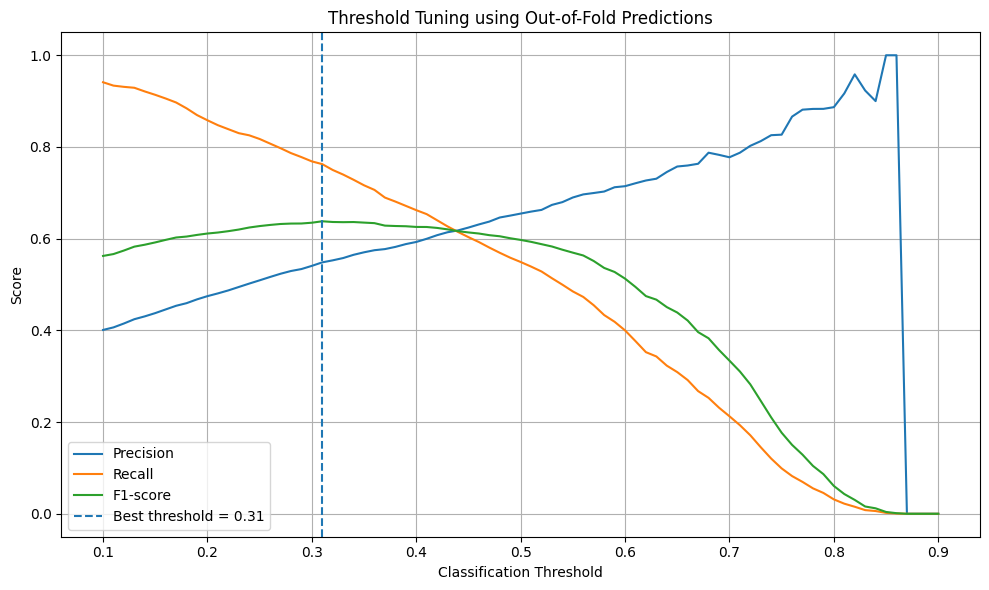

In [62]:
# =========================================================
# THRESHOLD PLOT
# =========================================================

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    label="F1-score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title(
    "Threshold Tuning using Out-of-Fold Predictions"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

Training Final model dengan menggunakan treshold tuning

In [63]:
# =========================================================
# FINAL TEST PREDICTION
# =========================================================

test_prob = best_lr.predict_proba(
    X_test
)[:, 1]


test_pred = (
    test_prob >= best_threshold
).astype(int)

In [64]:
# =========================================================
# FINAL METRICS
# =========================================================

final_metrics = {

    "accuracy": accuracy_score(
        y_test,
        test_pred
    ),

    "precision": precision_score(
        y_test,
        test_pred,
        zero_division=0
    ),

    "recall": recall_score(
        y_test,
        test_pred,
        zero_division=0
    ),

    "f1": f1_score(
        y_test,
        test_pred,
        zero_division=0
    ),

    "roc_auc": roc_auc_score(
        y_test,
        test_prob
    )
}


final_results = pd.DataFrame(
    [final_metrics],
    index=["Final Logistic Regression"]
)


print("\n=== FINAL TEST PERFORMANCE ===")

print(
    final_results.round(4)
)


=== FINAL TEST PERFORMANCE ===
                           accuracy  precision  recall      f1  roc_auc
Final Logistic Regression    0.7516     0.5226  0.7406  0.6128   0.8413


In [65]:
# =========================================================
# FINAL CLASSIFICATION REPORT
# =========================================================

print("\n=== FINAL CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "No Churn",
            "Churn"
        ],
        digits=4,
        zero_division=0
    )
)


=== FINAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    No Churn     0.8896    0.7556    0.8171      1035
       Churn     0.5226    0.7406    0.6128       374

    accuracy                         0.7516      1409
   macro avg     0.7061    0.7481    0.7150      1409
weighted avg     0.7922    0.7516    0.7629      1409




=== FINAL CONFUSION MATRIX ===
[[782 253]
 [ 97 277]]


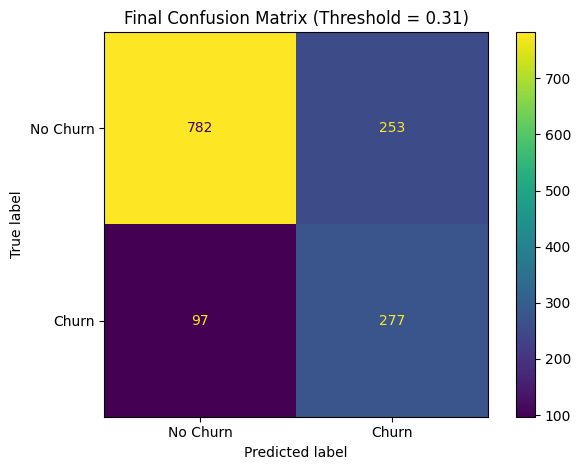

In [66]:
# =========================================================
# FINAL CONFUSION MATRIX
# =========================================================

cm_final = confusion_matrix(
    y_test,
    test_pred
)

print("\n=== FINAL CONFUSION MATRIX ===")
print(cm_final)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=[
        "No Churn",
        "Churn"
    ]
)

disp.plot()

plt.title(
    f"Final Confusion Matrix "
    f"(Threshold = {best_threshold:.2f})"
)

plt.tight_layout()
plt.show()

Perbandingan Antara Model Baseline dan Hasil Tuning

In [67]:
# =========================================================
# BASELINE VS FINAL
# =========================================================

baseline = {
    "accuracy": 0.805536,
    "precision": 0.657233,
    "recall": 0.558824,
    "f1": 0.604046,
    "roc_auc": 0.842013
}


comparison = pd.DataFrame({

    "Baseline Logistic Regression": baseline,

    "Final Logistic Regression": final_metrics

})


print("\n=== BASELINE VS FINAL ===")
print(
    comparison.round(4)
)


=== BASELINE VS FINAL ===
           Baseline Logistic Regression  Final Logistic Regression
accuracy                         0.8055                     0.7516
precision                        0.6572                     0.5226
recall                           0.5588                     0.7406
f1                               0.6040                     0.6128
roc_auc                          0.8420                     0.8413


Mengambil koefisien model untuk feature analisis

In [68]:
import pandas as pd
import numpy as np

feature_names = X_train.columns

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": best_lr.coef_[0]
})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()

coef_df = coef_df.sort_values(
    "abs_coefficient",
    ascending=False
)

print(coef_df.head(20))

                                 feature  coefficient  abs_coefficient
10           InternetService_Fiber optic     2.244445         2.244445
2                         MonthlyCharges    -1.748443         1.748443
25                     Contract_Two year    -1.375584         1.375584
8         MultipleLines_No phone service    -1.359465         1.359465
1                                 tenure    -1.282908         1.282908
23                   StreamingMovies_Yes     0.799592         0.799592
21                       StreamingTV_Yes     0.797992         0.797992
7                       PhoneService_Yes    -0.772435         0.772435
24                     Contract_One year    -0.699189         0.699189
9                      MultipleLines_Yes     0.574075         0.574075
3                           TotalCharges     0.558740         0.558740
28        PaymentMethod_Electronic check     0.382325         0.382325
26                  PaperlessBilling_Yes     0.369295         0.369295
12    

In [69]:
positive_features = (
    coef_df[coef_df["coefficient"] > 0]
    .sort_values("coefficient", ascending=False)
)

negative_features = (
    coef_df[coef_df["coefficient"] < 0]
    .sort_values("coefficient")
)

print("=== Fitur yang berkaitan dengan risiko churn lebih tinggi ===")
print(positive_features.head(10))

print("\n=== Fitur yang berkaitan dengan risiko churn lebih rendah ===")
print(negative_features.head(10))

=== Fitur yang berkaitan dengan risiko churn lebih tinggi ===
                           feature  coefficient  abs_coefficient
10     InternetService_Fiber optic     2.244445         2.244445
23             StreamingMovies_Yes     0.799592         0.799592
21                 StreamingTV_Yes     0.797992         0.797992
9                MultipleLines_Yes     0.574075         0.574075
3                     TotalCharges     0.558740         0.558740
28  PaymentMethod_Electronic check     0.382325         0.382325
26            PaperlessBilling_Yes     0.369295         0.369295
17            DeviceProtection_Yes     0.246206         0.246206
15                OnlineBackup_Yes     0.108134         0.108134
29      PaymentMethod_Mailed check     0.072511         0.072511

=== Fitur yang berkaitan dengan risiko churn lebih rendah ===
                                 feature  coefficient  abs_coefficient
2                         MonthlyCharges    -1.748443         1.748443
25                

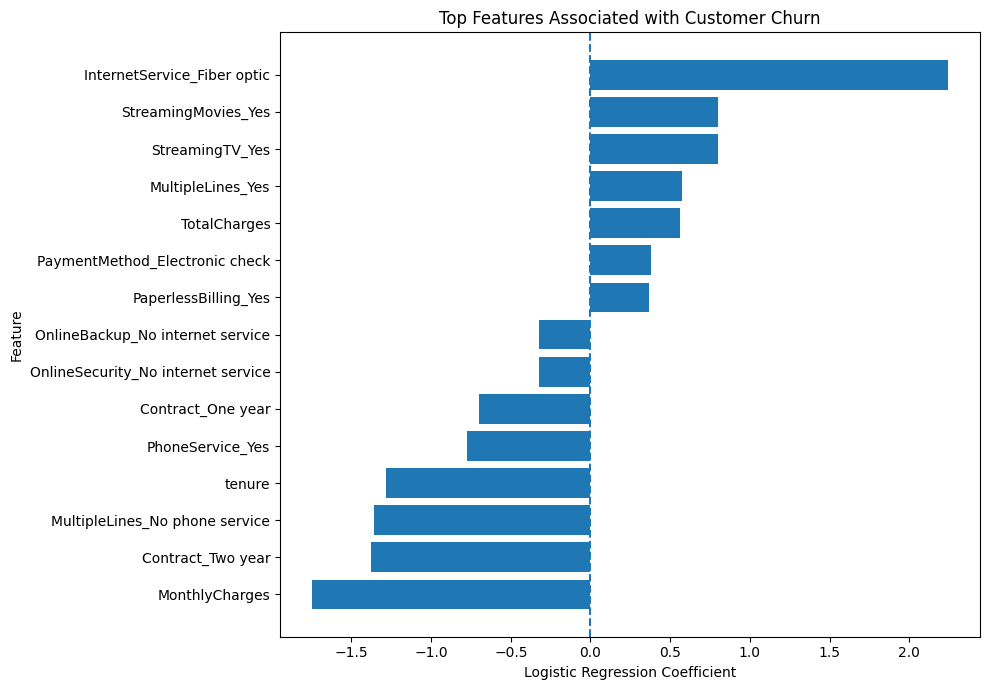

In [70]:
import matplotlib.pyplot as plt

top_features = coef_df.head(15).sort_values("coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["coefficient"]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top Features Associated with Customer Churn")

plt.tight_layout()
plt.show()

Melihat hubungan korelasi dari 3 fitur (tenure, monthly charge, total charge) dengan menggunakan Vif

In [71]:
!pip install statsmodels

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

vif_df = pd.DataFrame({
    "feature": numeric_features,
    "VIF": [
        variance_inflation_factor(
            X_train[numeric_features].values,
            i
        )
        for i in range(len(numeric_features))
    ]
})

print(vif_df.sort_values("VIF", ascending=False).round(3))

          feature    VIF
2    TotalCharges  9.575
0          tenure  5.868
1  MonthlyCharges  3.205



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Dari hasil perhitungan menggunakan Vif bahwa total charge dan tenure memiliki nilai korelasi yang tinggi yang dapat disimpulkan bahwa feature tenur dan total charge hampir membawa informasi yang sama terhadap model

In [72]:
corr_numeric = X_train[numeric_features].corr()

print(corr_numeric.round(3))

                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.257         0.829
MonthlyCharges   0.257           1.000         0.654
TotalCharges     0.829           0.654         1.000


Melakukan training model tanpa mengikutsertakan feature total charge

In [73]:
X_train_no_total = X_train.drop(columns=["TotalCharges"])
X_test_no_total = X_test.drop(columns=["TotalCharges"])

In [74]:
from sklearn.model_selection import cross_validate

lr_compare = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [75]:
scores_all = cross_validate(
    lr_compare,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

print("=== ALL FEATURES ===")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    values = scores_all[f"test_{metric}"]
    print(
        f"{metric:10s}: "
        f"{values.mean():.4f} ± {values.std():.4f}"
    )

=== ALL FEATURES ===
accuracy  : 0.8028 ± 0.0122
precision : 0.6548 ± 0.0277
recall    : 0.5438 ± 0.0409
f1        : 0.5935 ± 0.0302
roc_auc   : 0.8461 ± 0.0125


In [76]:
scores_no_total = cross_validate(
    lr_compare,
    X_train_no_total,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

print("\n=== WITHOUT TOTALCHARGES ===")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    values = scores_no_total[f"test_{metric}"]
    print(
        f"{metric:10s}: "
        f"{values.mean():.4f} ± {values.std():.4f}"
    )


=== WITHOUT TOTALCHARGES ===
accuracy  : 0.8012 ± 0.0109
precision : 0.6526 ± 0.0265
recall    : 0.5378 ± 0.0400
f1        : 0.5889 ± 0.0277
roc_auc   : 0.8449 ± 0.0121


Training Final Model dan Hyperparamter Tuning tanpa menggunakan feature total charge

In [77]:
X_model = X.drop(columns=["TotalCharges"])

In [78]:
from sklearn.model_selection import train_test_split

X_model = X.drop(columns=["TotalCharges"])

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [79]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"],
    "class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV ROC-AUC:")
print(f"{grid_search.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'C': 10, 'class_weight': None, 'penalty': 'l2', 'solver': 'liblinear'}

Best CV ROC-AUC:
0.8450


In [80]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import pandas as pd

best_lr = grid_search.best_estimator_

oof_prob = cross_val_predict(
    best_lr,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [81]:
thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:
    oof_pred = (oof_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_train, oof_pred),
        "precision": precision_score(
            y_train,
            oof_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_train,
            oof_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_train,
            oof_pred,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(
    threshold_df
    .sort_values("f1", ascending=False)
    .head(10)
    .round(4)
)

    threshold  accuracy  precision  recall      f1
22       0.32    0.7756     0.5578  0.7452  0.6380
24       0.34    0.7813     0.5697  0.7191  0.6357
23       0.33    0.7772     0.5617  0.7311  0.6353
21       0.31    0.7709     0.5501  0.7492  0.6344
20       0.30    0.7671     0.5437  0.7612  0.6343
25       0.35    0.7827     0.5735  0.7070  0.6333
26       0.36    0.7852     0.5792  0.6970  0.6327
19       0.29    0.7616     0.5352  0.7726  0.6324
18       0.28    0.7581     0.5299  0.7826  0.6319
17       0.27    0.7547     0.5251  0.7900  0.6309


In [82]:
# Best model dari GridSearch
best_lr = grid_search.best_estimator_

# Probabilitas churn pada TEST SET
test_prob = best_lr.predict_proba(X_test)[:, 1]

# Gunakan threshold hasil tuning
best_threshold = 0.32

test_pred = (
    test_prob >= best_threshold
).astype(int)

Hasil dari final model

In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

final_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(
        y_test,
        test_pred,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        test_pred,
        zero_division=0
    ),
    "f1": f1_score(
        y_test,
        test_pred,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test,
        test_prob
    )
}

print("=== FINAL TEST RESULTS ===")

for metric, value in final_metrics.items():
    print(f"{metric.upper():10s}: {value:.4f}")

=== FINAL TEST RESULTS ===
ACCURACY  : 0.7594
PRECISION : 0.5345
RECALL    : 0.7246
F1        : 0.6152
ROC_AUC   : 0.8382


In [84]:
print("\n=== CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test,
        test_pred,
        digits=4,
        target_names=["No Churn", "Churn"]
    )
)


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    No Churn     0.8858    0.7720    0.8250      1035
       Churn     0.5345    0.7246    0.6152       374

    accuracy                         0.7594      1409
   macro avg     0.7102    0.7483    0.7201      1409
weighted avg     0.7926    0.7594    0.7693      1409



In [85]:
cm = confusion_matrix(y_test, test_pred)

print("\n=== CONFUSION MATRIX ===")
print(cm)


=== CONFUSION MATRIX ===
[[799 236]
 [103 271]]


In [86]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, test_prob)

print(f"Final ROC-AUC: {roc_auc:.4f}")

Final ROC-AUC: 0.8382


Top Feature yang mempengaruhi/berkerolesai dengan Churn

In [87]:
import pandas as pd

coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": best_lr.coef_[0]
})

coefficients["Abs_Coefficient"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    "Abs_Coefficient",
    ascending=False
)

coefficients.head(15)

,Feature,Coefficient,Abs_Coefficient
9,InternetService_Fiber optic,2.258964,2.258964
2,MonthlyCharges,-1.616348,1.616348
7,MultipleLines_No phone service,-1.376017,1.376017
24,Contract_Two year,-1.358159,1.358159
22,StreamingMovies_Yes,0.818158,0.818158
20,StreamingTV_Yes,0.817348,0.817348
1,tenure,-0.803051,0.803051
6,PhoneService_Yes,-0.765726,0.765726
23,Contract_One year,-0.698599,0.698599
8,MultipleLines_Yes,0.594164,0.594164


In [88]:
positive_features = (
    coefficients[coefficients["Coefficient"] > 0]
    .sort_values("Coefficient", ascending=False)
)

negative_features = (
    coefficients[coefficients["Coefficient"] < 0]
    .sort_values("Coefficient")
)

print("=== FAKTOR YANG MENINGKATKAN PREDIKSI CHURN ===")
display(positive_features.head(10))

print("\n=== FAKTOR YANG MENURUNKAN PREDIKSI CHURN ===")
display(negative_features.head(10))

=== FAKTOR YANG MENINGKATKAN PREDIKSI CHURN ===


,Feature,Coefficient,Abs_Coefficient
9,InternetService_Fiber optic,2.258964,2.258964
22,StreamingMovies_Yes,0.818158,0.818158
20,StreamingTV_Yes,0.817348,0.817348
8,MultipleLines_Yes,0.594164,0.594164
27,PaymentMethod_Electronic check,0.383557,0.383557
25,PaperlessBilling_Yes,0.365346,0.365346
16,DeviceProtection_Yes,0.266996,0.266996
14,OnlineBackup_Yes,0.134950,0.134950
28,PaymentMethod_Mailed check,0.109578,0.109578
0,SeniorCitizen,0.053269,0.053269



=== FAKTOR YANG MENURUNKAN PREDIKSI CHURN ===


,Feature,Coefficient,Abs_Coefficient
2,MonthlyCharges,-1.616348,1.616348
7,MultipleLines_No phone service,-1.376017,1.376017
24,Contract_Two year,-1.358159,1.358159
1,tenure,-0.803051,0.803051
6,PhoneService_Yes,-0.765726,0.765726
23,Contract_One year,-0.698599,0.698599
19,StreamingTV_No internet service,-0.311864,0.311864
21,StreamingMovies_No internet service,-0.311864,0.311864
17,TechSupport_No internet service,-0.311864,0.311864
15,DeviceProtection_No internet service,-0.311864,0.311864


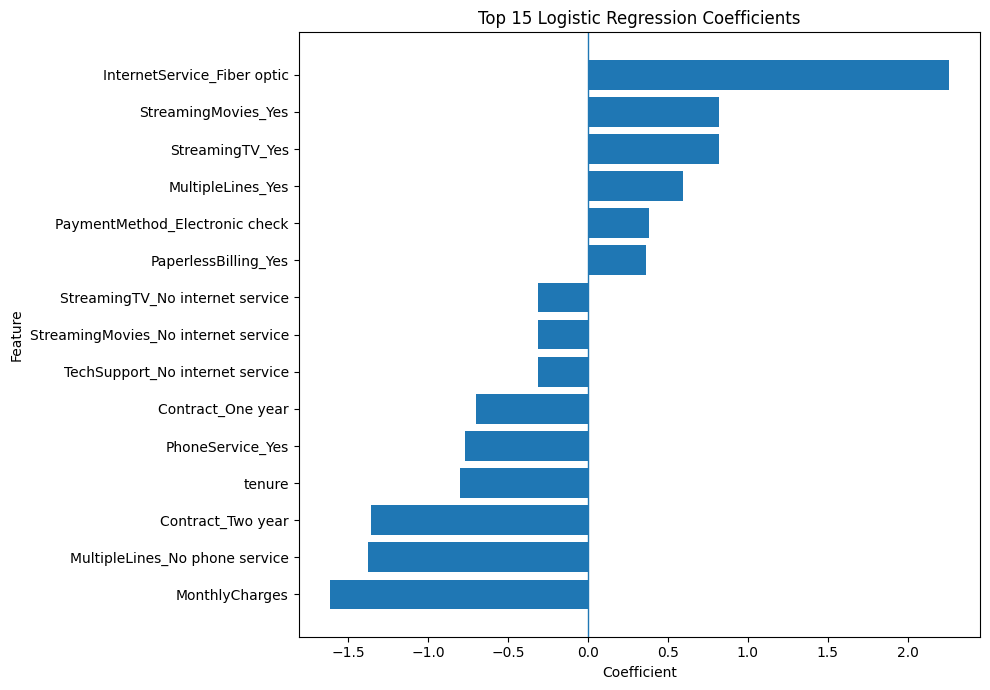

In [89]:
import matplotlib.pyplot as plt

top_features = coefficients.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linewidth=1)

plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [90]:
import joblib

model_package = {
    "model": best_lr,
    "threshold": 0.32,
    "model_name": "Logistic Regression",
    "best_params": grid_search.best_params_,
    "features": list(X_train.columns),
    "metrics": {
        "accuracy": 0.7594,
        "precision": 0.5345,
        "recall": 0.7246,
        "f1": 0.6152,
        "roc_auc": 0.8382
    }
}

joblib.dump(
    model_package,
    "../models/churn_model_final.pkl"
)

['../models/churn_model_final.pkl']

In [99]:
loaded_scaler = joblib.load("../models/preprocessing.pkl")

print("Mean:", loaded_scaler.mean_)
print("Scale:", loaded_scaler.scale_)

Mean: [1.62146812e-01 3.23711487e+01 6.47616925e+01 2.28191693e+03]
Scale: [3.68585436e-01 2.45577374e+01 3.00879109e+01 2.26510958e+03]
